In [2]:
import os, json, time, random, warnings, collections
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from gensim.models import Word2Vec
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
def set_seed():
    random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
set_seed()

ART_DIR = Path("model_artifacts"); ART_DIR.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [ ]:
DRIVE_ID = "1POmzYEQZgZVqJO3F_cyNcd4QmoNE_mCv"
candidates = [
    "bbc-news-data.tsv", "bbc-news-data.csv",
    "data/bbc-news-data.tsv", "data/bbc-news-data.csv",
    "/mnt/user-data/uploads/bbc-news-data.tsv",
    "/mnt/user-data/uploads/bbc-news-data.csv",
]
path = next((p for p in candidates if os.path.exists(p)), None)

if path is None:
    try:
        import gdown
    except ImportError as exc:
        raise FileNotFoundError(
            "Dataset not found. Upload bbc-news-data.tsv next to the notebook, "
            "or install gdown once to download it from Google Drive."
        ) from exc
    path = gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", "bbc-news-data.tsv", quiet=True)

if not path or not os.path.exists(path):
    raise FileNotFoundError("Dataset download failed. Upload bbc-news-data.tsv and rerun this cell.")

df = pd.read_csv(path, sep="\t")
print("Loaded from:", path, "| shape:", df.shape)
df.head()


In [4]:
df.info()
print()
print("Columns:", list(df.columns))

<class 'pandas.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  2225 non-null   str  
 1   filename  2225 non-null   str  
 2   title     2225 non-null   str  
 3   content   2225 non-null   str  
dtypes: str(4)
memory usage: 4.9 MB

Columns: ['category', 'filename', 'title', 'content']


In [5]:
missing = pd.DataFrame({
    "missing (NaN)": df.isna().sum(),
    "empty strings": [(df[c].astype(str).str.strip() == "").sum() for c in df.columns],
})
missing["% missing"] = (missing["missing (NaN)"] / len(df) * 100).round(2)
display(missing)
print("Total missing values:", int(df.isna().sum().sum()))

,missing (NaN),empty strings,% missing
category,0,0,0.0
filename,0,0,0.0
title,0,0,0.0
content,0,0,0.0


Total missing values: 0


,articles,percent
category,,
sport,511,23.0
business,510,22.9
politics,417,18.7
tech,401,18.0
entertainment,386,17.3


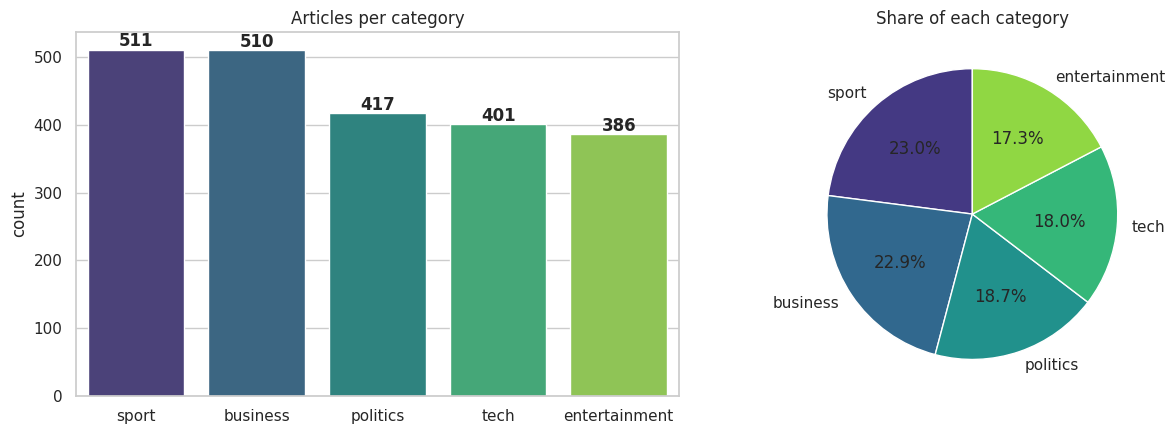

In [6]:
counts = df["category"].value_counts()
display(counts.to_frame("articles").assign(percent=(counts / len(df) * 100).round(1)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=counts.index, y=counts.values, palette="viridis", ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 5, str(v), ha="center", fontweight="bold")
ax[0].set_title("Articles per category"); ax[0].set_xlabel(""); ax[0].set_ylabel("count")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
          colors=sns.color_palette("viridis", len(counts)))
ax[1].set_title("Share of each category")
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
business,510.0,323.5,135.8,136.0,226.2,292.0,383.8,885.0
entertainment,386.0,325.2,261.9,138.0,219.0,256.5,354.8,3477.0
politics,417.0,448.9,300.2,84.0,312.0,434.0,525.0,4428.0
sport,511.0,324.4,188.1,108.0,199.0,282.0,404.5,1656.0
tech,401.0,497.4,239.8,157.0,333.0,441.0,624.0,2964.0


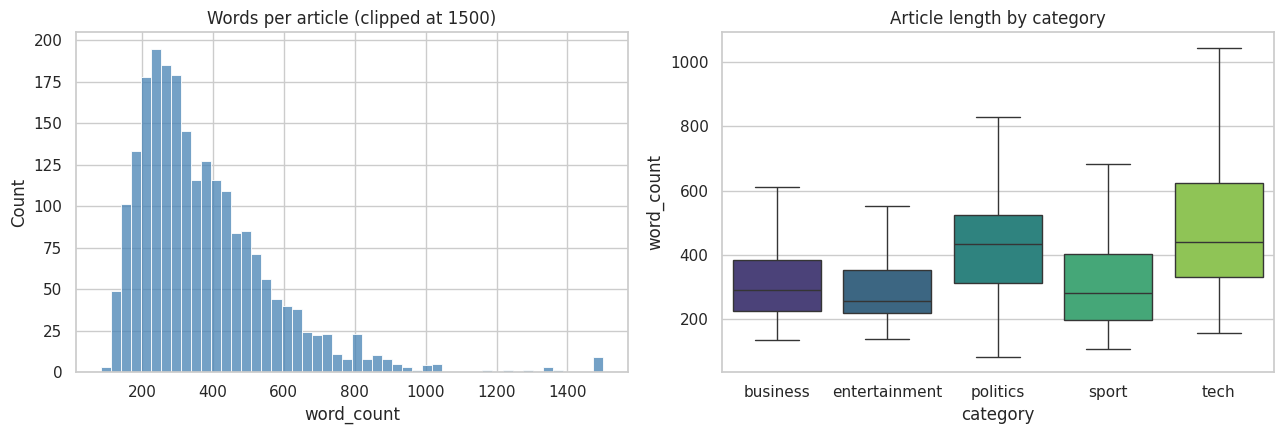

In [7]:
df["word_count"] = df["content"].str.split().str.len()
display(df.groupby("category")["word_count"].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["word_count"].clip(upper=1500), bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("Words per article (clipped at 1500)")
sns.boxplot(data=df, x="category", y="word_count", palette="viridis", ax=ax[1], showfliers=False)
ax[1].set_title("Article length by category")
plt.tight_layout(); plt.show()

In [8]:
dup_mask = df.duplicated(subset=["content"], keep="first")
conflicting = (df.groupby("content")["category"].nunique() > 1).sum()
print(f"Duplicate article bodies : {dup_mask.sum()}")
print(f"Duplicates with conflicting labels: {conflicting}")
print("Duplicates per category:\n", df[dup_mask]["category"].value_counts().to_string())

Duplicate article bodies : 133
Duplicates with conflicting labels: 0
Duplicates per category:
 category
tech             64
politics         22
entertainment    20
sport            17
business         10


In [9]:
df = df.drop_duplicates(subset=["content"], keep="first").reset_index(drop=True)
# the model reads the headline together with the body
df["text"] = df["title"].fillna("") + ". " + df["content"].fillna("")
print("After de-duplication:", df.shape)
print(df["category"].value_counts().to_string())

After de-duplication: (2092, 6)
category
business         500
sport            494
politics         395
entertainment    366
tech             337


In [10]:
import re

def clean_text(text):
    """Lowercase -> remove punctuation -> remove digits/symbols -> collapse whitespace."""
    text = str(text).lower()
    text = re.sub(r"[!\"#$%&'()*+,\-./:;<=>?@\[\\\]^_`{|}~“”‘’–—…£€]", " ", text)  # punctuation
    text = re.sub(r"[^a-z\s]", " ", text)                                            # digits / other symbols
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    """Whitespace tokenisation of the already-cleaned text."""
    return text.split()

def preprocess(text, stopwords):
    """Full pipeline: clean -> tokenize -> remove stop-words and 1-letter tokens."""
    return [t for t in tokenize(clean_text(text)) if t not in stopwords and len(t) > 1]

def encode(tokens, word2idx, maxlen):
    """Tokens -> integer ids (0 = padding, 1 = out-of-vocabulary), truncated/padded to maxlen."""
    ids = [word2idx.get(t, 1) for t in tokens][:maxlen]
    return ids + [0] * (maxlen - len(ids))

In [11]:
nltk.download("stopwords", quiet=True)
STOPWORDS = set(stopwords.words("english"))
print(len(STOPWORDS), "stop-words, e.g.", sorted(STOPWORDS)[:12])

sample = df.loc[0, "text"][:300]
print("\nORIGINAL :", sample)
print("\nLOWER + NO PUNCT :", clean_text(sample))
print("\nTOKENS (stop-words removed):", preprocess(sample, STOPWORDS))

198 stop-words, e.g. ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any']

ORIGINAL : Ad sales boost Time Warner profit.  Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.  The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and high

LOWER + NO PUNCT : ad sales boost time warner profit quarterly profits at us media giant timewarner jumped to bn m for the three months to december from m year earlier the firm which is now one of the biggest investors in google benefited from sales of high speed internet connections and high

TOKENS (stop-words removed): ['ad', 'sales', 'boost', 'time', 'warner', 'profit', 'quarterly', 'profits', 'us', 'media', 'giant', 'timewarner', 'jumped', 'bn', 'three', 'months', 'december', 'year', 'earlier', 'firm', 'one', 'biggest', 'investors', 'google', 'benefited', 'sale

Average tokens per article after cleaning: 217.6
Empty after cleaning: 0


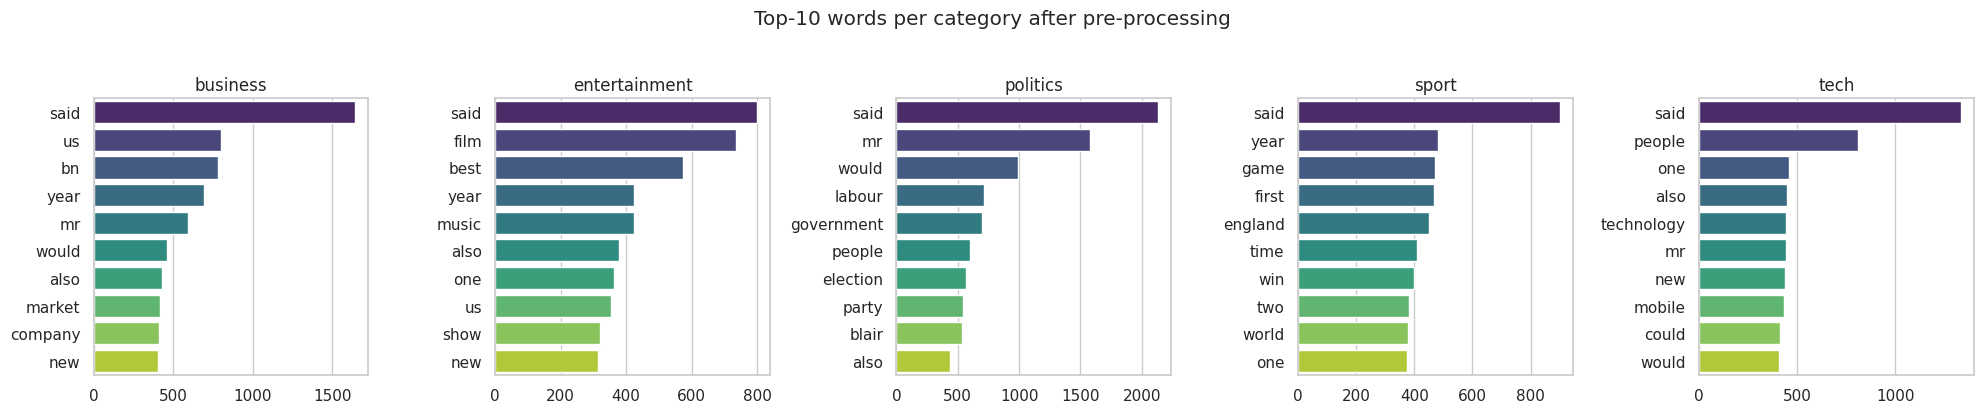

In [12]:
df["tokens"] = df["text"].apply(lambda t: preprocess(t, STOPWORDS))
df["clean_text"] = df["tokens"].str.join(" ")
df["n_tokens"] = df["tokens"].str.len()
print("Average tokens per article after cleaning:", round(df["n_tokens"].mean(), 1))
print("Empty after cleaning:", (df["n_tokens"] == 0).sum())

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=False)
for ax, cat in zip(axes, sorted(df["category"].unique())):
    cnt = collections.Counter(w for toks in df.loc[df.category == cat, "tokens"] for w in toks).most_common(10)
    sns.barplot(x=[c for _, c in cnt], y=[w for w, _ in cnt], ax=ax, palette="viridis")
    ax.set_title(cat)
plt.suptitle("Top-10 words per category after pre-processing", y=1.03); plt.tight_layout(); plt.show()

In [13]:
le = LabelEncoder()
y_all = le.fit_transform(df["category"])
CLASSES = list(le.classes_); N_CLASSES = len(CLASSES)

idx = np.arange(len(df))
idx_tv, idx_test = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_tv, test_size=0.125, stratify=y_all[idx_tv], random_state=SEED)

texts_train, texts_val, texts_test = (df["clean_text"].iloc[i] for i in (idx_train, idx_val, idx_test))
tok_train, tok_val, tok_test = (df["tokens"].iloc[i].tolist() for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

print("Classes:", dict(enumerate(CLASSES)))
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}")
print("Test class balance:", np.bincount(y_test))

Classes: {0: 'business', 1: 'entertainment', 2: 'politics', 3: 'sport', 4: 'tech'}
train=1463  val=210  test=419
Test class balance: [100  73  79  99  68]


In [14]:
results, preds, histories, models = [], {}, {}, {}
val_scores = {}

def build_mlp(input_dim):
    return keras.Sequential([
        layers.Input((input_dim,)),
        layers.Dense(256, activation="relu"), layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),  layers.Dropout(0.3),
        layers.Dense(N_CLASSES, activation="softmax"),
    ])

def fit(model, Xtr, ytr, Xva, yva, epochs=40, batch=32):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=batch,
                  callbacks=[es], verbose=0)
    secs = time.time() - t0
    print(f"  stopped after {len(h.epoch)} epochs ({secs:.0f}s) | best val_loss={min(h.history['val_loss']):.4f}"
          f" | val_acc={h.history['val_accuracy'][int(np.argmin(h.history['val_loss']))]:.4f}")
    return h, secs

def record(name, features, family, model, Xva, Xte, hist, secs):
    p_te = model.predict(Xte, verbose=0).argmax(1)
    p_va = model.predict(Xva, verbose=0).argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_test, p_te, average="weighted", zero_division=0)
    mf = precision_recall_fscore_support(y_test, p_te, average="macro", zero_division=0)[2]
    results.append({"Model": name, "Features": features, "Type": family,
                    "Accuracy": accuracy_score(y_test, p_te), "Precision": p, "Recall": r,
                    "F1-score": f, "Macro F1": mf, "Params": int(model.count_params()),
                    "Epochs": len(hist.epoch), "Train time (s)": round(secs, 1)})
    val_scores[name] = accuracy_score(y_val, p_va)
    preds[name], histories[name], models[name] = p_te, hist.history, model
    print(f"  TEST  acc={results[-1]['Accuracy']:.4f}  P={p:.4f}  R={r:.4f}  F1={f:.4f}")

In [15]:
set_seed()
bow = CountVectorizer(max_features=5000, min_df=2)
Xb_tr = bow.fit_transform(texts_train).toarray().astype("float32")
Xb_va = bow.transform(texts_val).toarray().astype("float32")
Xb_te = bow.transform(texts_test).toarray().astype("float32")
print("BoW matrix:", Xb_tr.shape)

m = build_mlp(Xb_tr.shape[1])
h, s = fit(m, Xb_tr, y_train, Xb_va, y_val)
record("NN + BoW", "Bag of Words", "NN", m, Xb_va, Xb_te, h, s)

BoW matrix: (1463, 5000)


  stopped after 12 epochs (9s) | best val_loss=0.0801 | val_acc=0.9667


  TEST  acc=0.9737  P=0.9745  R=0.9737  F1=0.9739


In [16]:
set_seed()
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xt_tr = tfidf.fit_transform(texts_train).toarray().astype("float32")
Xt_va = tfidf.transform(texts_val).toarray().astype("float32")
Xt_te = tfidf.transform(texts_test).toarray().astype("float32")
print("TF-IDF matrix:", Xt_tr.shape)

m = build_mlp(Xt_tr.shape[1])
h, s = fit(m, Xt_tr, y_train, Xt_va, y_val)
record("NN + TF-IDF", "TF-IDF", "NN", m, Xt_va, Xt_te, h, s)

TF-IDF matrix: (1463, 5000)


  stopped after 12 epochs (9s) | best val_loss=0.0723 | val_acc=0.9667


  TEST  acc=0.9761  P=0.9768  R=0.9761  F1=0.9762


In [17]:
set_seed()
w2v = Word2Vec(sentences=tok_train, vector_size=100, window=5, min_count=2, sg=1,
               workers=1, epochs=30, seed=SEED)
print("Word2Vec vocabulary:", len(w2v.wv))
print("Most similar to 'football':", [w for w, _ in w2v.wv.most_similar("football", topn=5)])
print("Most similar to 'government':", [w for w, _ in w2v.wv.most_similar("government", topn=5)])

def doc_vector(tokens):
    vecs = [w2v.wv[t] for t in tokens if t in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

Xw_tr = np.vstack([doc_vector(t) for t in tok_train])
Xw_va = np.vstack([doc_vector(t) for t in tok_val])
Xw_te = np.vstack([doc_vector(t) for t in tok_test])
scaler = StandardScaler().fit(Xw_tr)
Xw_tr, Xw_va, Xw_te = (scaler.transform(x).astype("float32") for x in (Xw_tr, Xw_va, Xw_te))

m = build_mlp(Xw_tr.shape[1])
h, s = fit(m, Xw_tr, y_train, Xw_va, y_val)
record("NN + Word2Vec", "Word2Vec (avg)", "NN", m, Xw_va, Xw_te, h, s)

Word2Vec vocabulary: 15061
Most similar to 'football': ['michels', 'club', 'nfl', 'hkrfu', 'slanging']
Most similar to 'government': ['authoritarian', 'subsidised', 'rewriting', 'proposes', 'propaganda']


  stopped after 14 epochs (5s) | best val_loss=0.0938 | val_acc=0.9714


  TEST  acc=0.9642  P=0.9653  R=0.9642  F1=0.9644


In [18]:
freq = collections.Counter(w for toks in tok_train for w in toks)
vocab_words = [w for w, c in freq.most_common(20000) if c >= 2]
word2idx = {w: i + 2 for i, w in enumerate(vocab_words)}
VOCAB_SIZE = len(word2idx) + 2
MAXLEN = int(min(400, np.percentile([len(t) for t in tok_train], 90)))
print("Vocabulary size:", VOCAB_SIZE, "| sequence length:", MAXLEN)

def to_seq(tok_lists):
    return np.array([encode(t, word2idx, MAXLEN) for t in tok_lists], dtype="int32")
S_tr, S_va, S_te = to_seq(tok_train), to_seq(tok_val), to_seq(tok_test)
print("Sequence tensor:", S_tr.shape)

# embedding matrix initialised from the Word2Vec model trained above
emb_matrix = np.random.normal(0, 0.05, (VOCAB_SIZE, w2v.vector_size)).astype("float32")
emb_matrix[0] = 0
hit = 0
for w, i in word2idx.items():
    if w in w2v.wv:
        emb_matrix[i] = w2v.wv[w]; hit += 1
print(f"{hit}/{len(word2idx)} vocabulary words have a Word2Vec vector")

Vocabulary size: 15063 | sequence length: 353
Sequence tensor: (1463, 353)
15061/15061 vocabulary words have a Word2Vec vector


In [19]:
def build_rnn(cell="lstm", pretrained=True):
    inp = layers.Input((MAXLEN,), dtype="int32")
    init = keras.initializers.Constant(emb_matrix) if pretrained else "uniform"
    x = layers.Embedding(VOCAB_SIZE, w2v.vector_size, embeddings_initializer=init, mask_zero=True)(inp)
    x = layers.Dropout(0.3)(x)
    rnn = layers.LSTM(64) if cell == "lstm" else layers.GRU(64)
    x = layers.Bidirectional(rnn)(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out)

In [20]:
set_seed()
rnn_a = build_rnn("lstm", pretrained=True)
rnn_a.summary()
h, s = fit(rnn_a, S_tr, y_train, S_va, y_val, epochs=30)
record("RNN (BiLSTM) + Word2Vec", "Word2Vec embeddings (sequence)", "RNN", rnn_a, S_va, S_te, h, s)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 353)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 353, 100)  │  1,506,300 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 353, 100)  │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 353)       │          0 │ input_layer_3[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     84,480 │ dropout_6[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │      8,256 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 5)         │        325 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,599,361 (6.10 MB)

 Trainable params: 1,599,361 (6.10 MB)

 Non-trainable params: 0 (0.00 B)

E0000 00:00:1791988823.846417     120 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


  stopped after 10 epochs (208s) | best val_loss=0.1007 | val_acc=0.9762


  TEST  acc=0.9570  P=0.9578  R=0.9570  F1=0.9570


In [21]:
set_seed()
rnn_b = build_rnn("gru", pretrained=False)
h, s = fit(rnn_b, S_tr, y_train, S_va, y_val, epochs=30)
record("RNN (BiGRU) + learned embeddings", "Learned embeddings (sequence)", "RNN", rnn_b, S_va, S_te, h, s)

  stopped after 19 epochs (386s) | best val_loss=0.3218 | val_acc=0.9333


  TEST  acc=0.9451  P=0.9455  R=0.9451  F1=0.9450


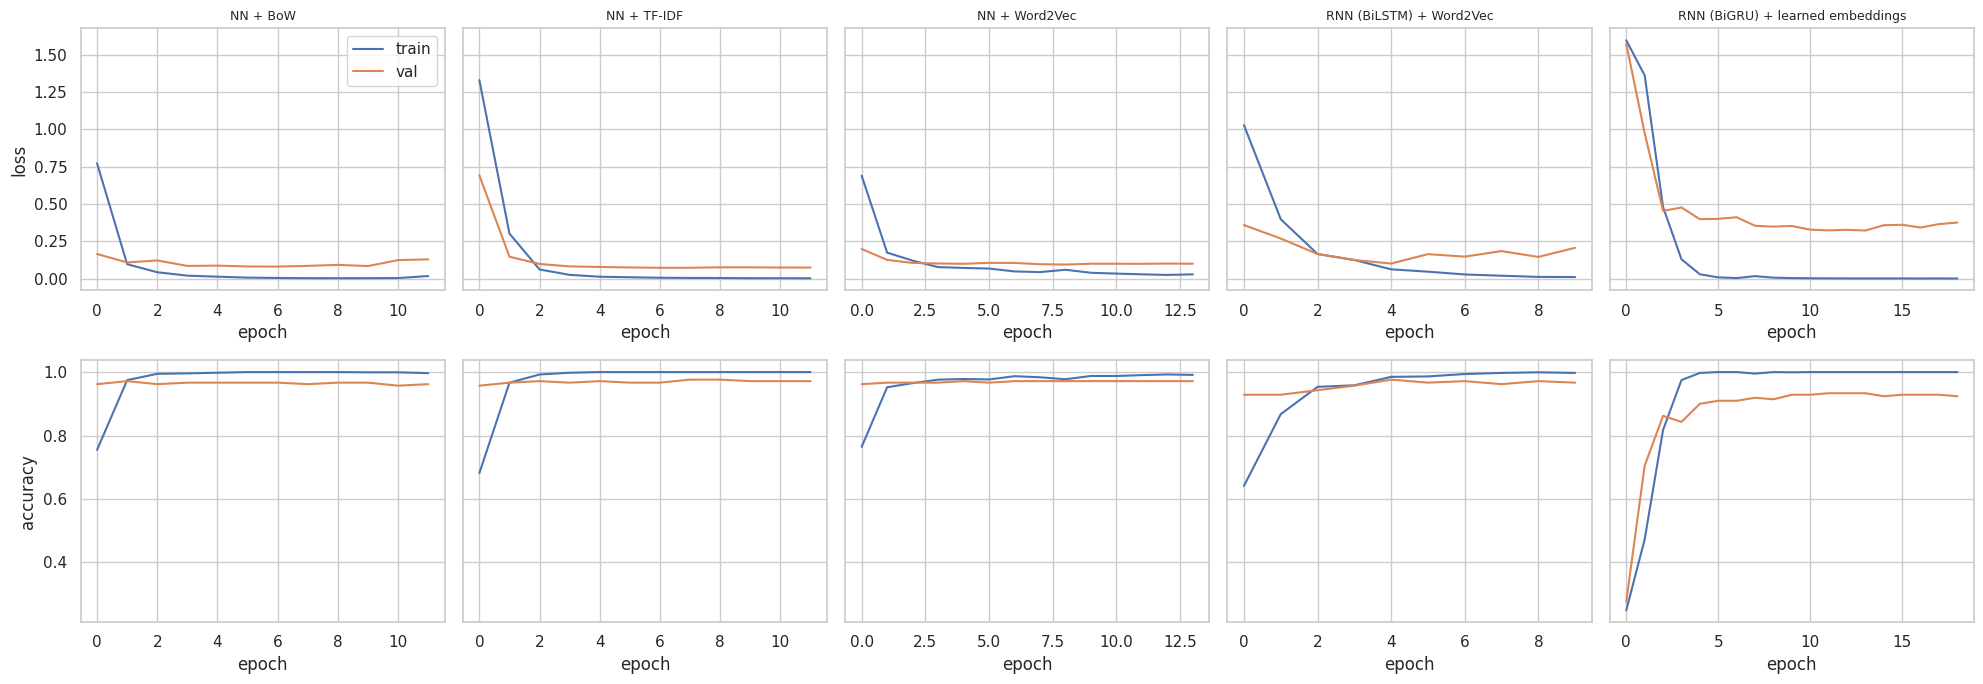

In [22]:
fig, axes = plt.subplots(2, len(histories), figsize=(4 * len(histories), 7), sharey="row")
for j, (name, h) in enumerate(histories.items()):
    axes[0, j].plot(h["loss"], label="train"); axes[0, j].plot(h["val_loss"], label="val")
    axes[0, j].set_title(name, fontsize=9); axes[0, j].set_xlabel("epoch")
    axes[1, j].plot(h["accuracy"], label="train"); axes[1, j].plot(h["val_accuracy"], label="val")
    axes[1, j].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss"); axes[1, 0].set_ylabel("accuracy"); axes[0, 0].legend()
plt.tight_layout(); plt.show()

,Type,Features,Accuracy,Precision,Recall,F1-score,Macro F1,Val accuracy,Params,Train time (s)
Model,,,,,,,,,,
NN + BoW,NN,Bag of Words,0.9737,0.9745,0.9737,0.9739,0.9729,0.9667,1297029,9.300000
NN + TF-IDF,NN,TF-IDF,0.9761,0.9768,0.9761,0.9762,0.9759,0.9667,1297029,9.200000
NN + Word2Vec,NN,Word2Vec (avg),0.9642,0.9653,0.9642,0.9644,0.9635,0.9714,42629,4.800000
RNN (BiLSTM) + Word2Vec,RNN,Word2Vec embeddings (sequence),0.9570,0.9578,0.9570,0.9570,0.9565,0.9762,1599361,208.400000
RNN (BiGRU) + learned embeddings,RNN,Learned embeddings (sequence),0.9451,0.9455,0.9451,0.9450,0.9436,0.9333,1578625,386.000000


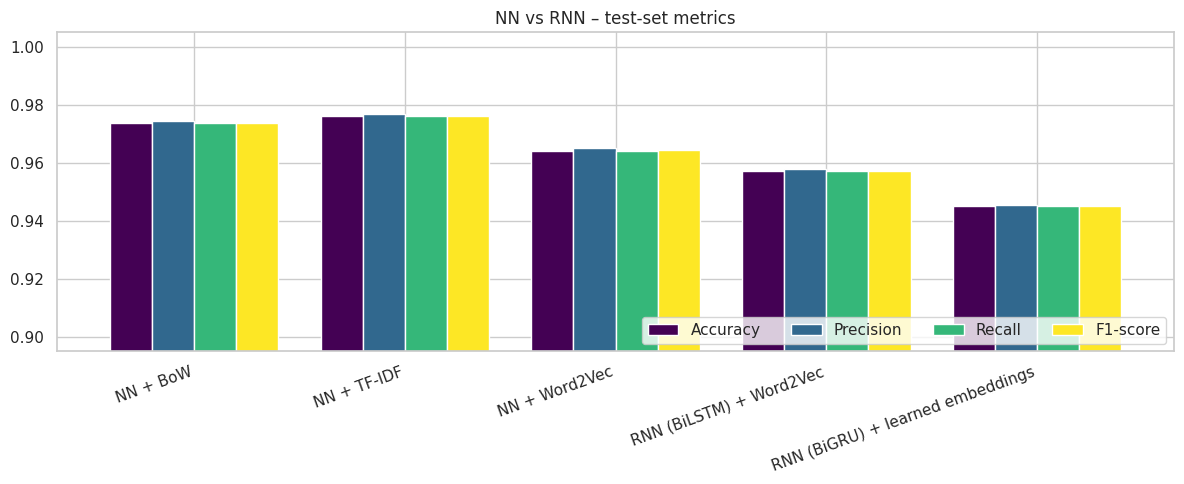

In [23]:
res = pd.DataFrame(results).set_index("Model")
res["Val accuracy"] = pd.Series(val_scores)
show = res[["Type", "Features", "Accuracy", "Precision", "Recall", "F1-score", "Macro F1", "Val accuracy", "Params", "Train time (s)"]]
display(show.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1-score", "Macro F1", "Val accuracy"]})
        .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1-score"], color="#c8e6c9"))

ax = res[["Accuracy", "Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(12, 5), colormap="viridis", width=0.8)
ax.set_ylim(max(0, res[["Accuracy", "F1-score"]].min().min() - 0.05), 1.005)
ax.set_title("NN vs RNN – test-set metrics"); ax.set_xlabel(""); plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right", ncol=4); plt.tight_layout(); plt.show()

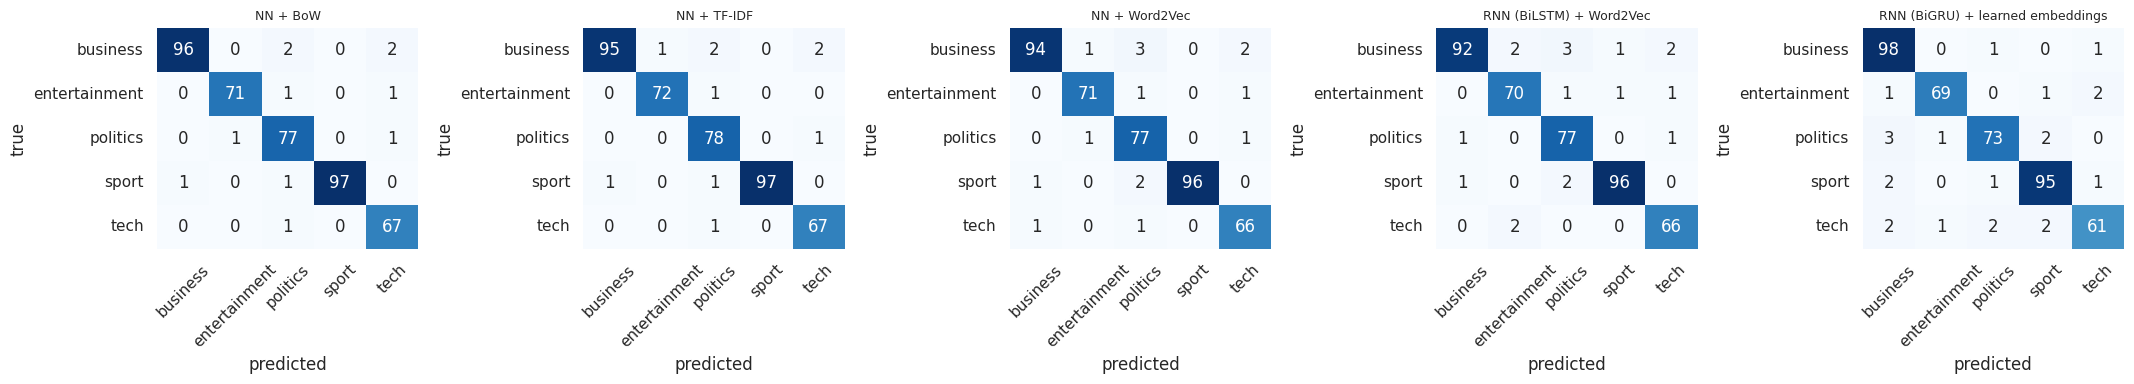

In [24]:
n = len(preds)
fig, axes = plt.subplots(1, n, figsize=(4.3 * n, 4))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(name, fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Deployed model: RNN (BiLSTM) + Word2Vec | validation accuracy: 0.9762

               precision    recall  f1-score   support

     business     0.9787    0.9200    0.9485       100
entertainment     0.9459    0.9589    0.9524        73
     politics     0.9277    0.9747    0.9506        79
        sport     0.9796    0.9697    0.9746        99
         tech     0.9429    0.9706    0.9565        68

     accuracy                         0.9570       419
    macro avg     0.9550    0.9588    0.9565       419
 weighted avg     0.9578    0.9570    0.9570       419



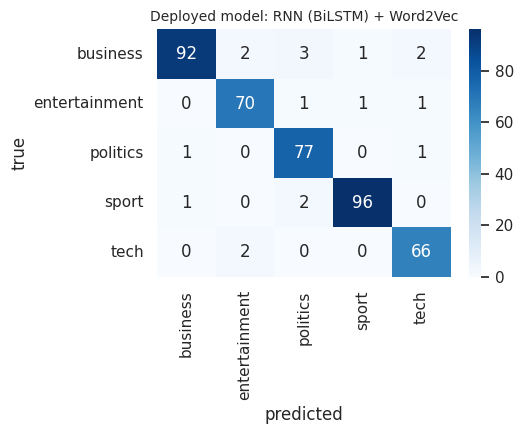

In [25]:
rnn_names = [r["Model"] for r in results if r["Type"] == "RNN"]
DEPLOY = max(rnn_names, key=lambda n: val_scores[n])
deploy_model = models[DEPLOY]
print("Deployed model:", DEPLOY, "| validation accuracy:", round(val_scores[DEPLOY], 4))
print()
print(classification_report(y_test, preds[DEPLOY], target_names=CLASSES, digits=4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, preds[DEPLOY]), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title(f"Deployed model: {DEPLOY}", fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(ART_DIR / "confusion_matrix_rnn.png", dpi=130); plt.show()

In [26]:
# Where does the deployed model go wrong? (error analysis)
wrong = np.where(preds[DEPLOY] != y_test)[0]
print(f"{len(wrong)} / {len(y_test)} test articles misclassified\n")
for k in wrong[:5]:
    row = df.iloc[idx_test[k]]
    print(f"TRUE={row['category']:<14} PRED={CLASSES[preds[DEPLOY][k]]:<14} | {row['title']}")

18 / 419 test articles misclassified

TRUE=politics       PRED=tech           | UK firms 'embracing e-commerce'
TRUE=sport          PRED=politics       | Calder fears for Scottish rugby
TRUE=business       PRED=politics       | Call to overhaul UK state pension
TRUE=business       PRED=tech           | Card fraudsters 'targeting web'
TRUE=business       PRED=sport          | McDonald's boss Bell dies aged 44


In [27]:
best = res["F1-score"].idxmax()
best_rnn = res[res["Type"] == "RNN"]["F1-score"].idxmax()
rep = classification_report(y_test, preds[DEPLOY], target_names=CLASSES, output_dict=True)
worst_cls = min(CLASSES, key=lambda c: rep[c]["f1-score"])
acc = res.loc[DEPLOY, "Accuracy"]

probs = deploy_model.predict(S_te, verbose=0)
conf = probs.max(1)
correct = probs.argmax(1) == y_test
mask = conf >= 0.70
print(f"Best model overall (F1)        : {best}  ({res.loc[best, 'F1-score']:.4f})")
print(f"Best RNN (F1)                  : {best_rnn}  ({res.loc[best_rnn, 'F1-score']:.4f})")
print(f"Deployed RNN                   : {DEPLOY}  (accuracy {acc:.2%})")
print(f"Weakest category (F1)          : {worst_cls}  ({rep[worst_cls]['f1-score']:.3f})")
print()
print("Human-in-the-loop simulation with a 0.70 confidence threshold:")
print(f"  auto-tagged   : {mask.mean():.1%} of articles, accuracy on those = {correct[mask].mean():.2%}")
print(f"  sent to editor: {1 - mask.mean():.1%} of articles")
print(f"  (manual effort cut by ~{mask.mean():.0%}, while the accuracy of auto-tagged content rises from {correct.mean():.2%} to {correct[mask].mean():.2%})")

Best model overall (F1)        : NN + TF-IDF  (0.9762)
Best RNN (F1)                  : RNN (BiLSTM) + Word2Vec  (0.9570)
Deployed RNN                   : RNN (BiLSTM) + Word2Vec  (accuracy 95.70%)
Weakest category (F1)          : business  (0.948)

Human-in-the-loop simulation with a 0.70 confidence threshold:
  auto-tagged   : 96.9% of articles, accuracy on those = 96.55%
  sent to editor: 3.1% of articles
  (manual effort cut by ~97%, while the accuracy of auto-tagged content rises from 95.70% to 96.55%)


In [ ]:
# Save only the selected model and files required by the Streamlit dashboard.
# The other models remain available in memory for the comparisons above.
deploy_model.save(ART_DIR / "rnn_model.keras")
(ART_DIR / "vocab.json").write_text(json.dumps({"word2idx": word2idx, "maxlen": MAXLEN}), encoding="utf-8")
(ART_DIR / "label_classes.json").write_text(json.dumps(CLASSES), encoding="utf-8")
(ART_DIR / "stopwords.json").write_text(json.dumps(sorted(STOPWORDS)), encoding="utf-8")

# One real test article per category for the dashboard's sample buttons.
samples = {}
for c in CLASSES:
    class_id = int(le.transform([c])[0])
    candidate = next(
        i for i in idx_test
        if y_all[i] == class_id and 80 < df["n_tokens"].iloc[i] < 250
    )
    samples[c] = str(df["text"].iloc[candidate])
(ART_DIR / "samples.json").write_text(json.dumps(samples, ensure_ascii=False), encoding="utf-8")

metrics = {
    "results": [
        {
            "Model": name,
            "Type": row["Type"],
            "Accuracy": float(row["Accuracy"]),
            "Precision": float(row["Precision"]),
            "Recall": float(row["Recall"]),
            "F1-score": float(row["F1-score"]),
            "Macro F1": float(row["Macro F1"]),
        }
        for name, row in res.iterrows()
    ],
    "deployed": {
        "name": DEPLOY,
        "accuracy": float(res.loc[DEPLOY, "Accuracy"]),
        "f1": float(res.loc[DEPLOY, "F1-score"]),
        "report": {
            k: v for k, v in classification_report(
                y_test, preds[DEPLOY], target_names=CLASSES, output_dict=True
            ).items() if k != "accuracy"
        },
    },
}
(ART_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Dashboard artifacts:", sorted(p.name for p in ART_DIR.iterdir() if p.is_file()))


In [29]:
%%writefile news_utils.py
"""Shared pre-processing + inference code (identical to the notebook's pre-processing)."""
import re

def clean_text(text):
    """Lowercase -> remove punctuation -> remove digits/symbols -> collapse whitespace."""
    text = str(text).lower()
    text = re.sub(r"[!\"#$%&'()*+,\-./:;<=>?@\[\\\]^_`{|}~“”‘’–—…£€]", " ", text)  # punctuation
    text = re.sub(r"[^a-z\s]", " ", text)                                            # digits / other symbols
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    """Whitespace tokenisation of the already-cleaned text."""
    return text.split()

def preprocess(text, stopwords):
    """Full pipeline: clean -> tokenize -> remove stop-words and 1-letter tokens."""
    return [t for t in tokenize(clean_text(text)) if t not in stopwords and len(t) > 1]

def encode(tokens, word2idx, maxlen):
    """Tokens -> integer ids (0 = padding, 1 = out-of-vocabulary), truncated/padded to maxlen."""
    ids = [word2idx.get(t, 1) for t in tokens][:maxlen]
    return ids + [0] * (maxlen - len(ids))


# ---------- model loading / inference (used by the dashboard) ----------
import json
from pathlib import Path
import numpy as np

def load_artifacts(artifact_dir):
    from tensorflow import keras
    d = Path(artifact_dir)
    cfg = json.loads((d / "vocab.json").read_text())
    return {
        "model": keras.models.load_model(d / "rnn_model.keras"),
        "word2idx": cfg["word2idx"],
        "maxlen": cfg["maxlen"],
        "classes": json.loads((d / "label_classes.json").read_text()),
        "stopwords": set(json.loads((d / "stopwords.json").read_text())),
    }

def predict_proba(texts, art):
    seqs = np.array([encode(preprocess(t, art["stopwords"]), art["word2idx"], art["maxlen"]) for t in texts],
                    dtype="int32")
    return art["model"].predict(seqs, verbose=0)


Writing news_utils.py


In [30]:
%%writefile app.py
import json
from pathlib import Path

import numpy as np
import pandas as pd
import streamlit as st

from news_utils import load_artifacts, predict_proba, preprocess

ART_DIR = Path(__file__).parent / "model_artifacts"
CONF_THRESHOLD = 0.70   # below this, route the article to a human editor

st.set_page_config(page_title="FlipItNews | AI News Categoriser", page_icon="📰", layout="wide")


@st.cache_resource(show_spinner="Loading trained RNN model ...")
def get_art():
    return load_artifacts(ART_DIR)


@st.cache_data
def get_json(name):
    p = ART_DIR / name
    return json.loads(p.read_text()) if p.exists() else None


art = get_art()
classes = art["classes"]
metrics = get_json("metrics.json")
samples = get_json("samples.json") or {}

# ------------------------------------------------------------------ header
st.title("📰 FlipItNews – Automated News Categoriser")
st.caption("A bidirectional recurrent neural network (Word2Vec-initialised) that tags an article with a "
           "newsroom category so it can be filed, searched and personalised without manual labelling.")

with st.sidebar:
    st.header("About the model")
    if metrics:
        dep = metrics["deployed"]
        st.markdown(f"**Architecture:** {dep['name']}")
        c1, c2 = st.columns(2)
        c1.metric("Test accuracy", f"{dep['accuracy']:.1%}")
        c2.metric("Weighted F1", f"{dep['f1']:.1%}")
    st.markdown("**Categories:** " + ", ".join(f"`{c}`" for c in classes))
    threshold = st.slider("Auto-publish confidence threshold", 0.30, 0.95, CONF_THRESHOLD, 0.05,
                          help="Predictions below this confidence are flagged for editorial review.")

tab1, tab2, tab3 = st.tabs(["🔍 Classify an article", "🗂️ Batch classify (CSV)", "📊 Model performance"])

# ------------------------------------------------------------------ tab 1
with tab1:
    if "text" not in st.session_state:
        st.session_state["text"] = ""
    if samples:
        st.write("Try a sample article:")
        cols = st.columns(len(samples))
        for col, (cat, txt) in zip(cols, samples.items()):
            if col.button(f"Sample: {cat}"):
                st.session_state["text"] = txt

    text = st.text_area("Paste a headline + article body", key="text", height=260,
                        placeholder="e.g. The Bank of England held interest rates on Thursday as inflation ...")

    if st.button("Classify article", type="primary"):
        n_tokens = len(preprocess(text, art["stopwords"]))
        if n_tokens < 5:
            st.warning("Please enter a longer article (at least a few meaningful words).")
        else:
            probs = predict_proba([text], art)[0]
            order = np.argsort(probs)[::-1]
            top, conf = classes[order[0]], float(probs[order[0]])
            left, right = st.columns([1, 1.4])
            with left:
                st.subheader(f"Predicted category: {top.title()}")
                st.metric("Confidence", f"{conf:.1%}")
                if conf >= threshold:
                    st.success("High confidence – can be auto-tagged and published.")
                else:
                    runner = classes[order[1]]
                    st.warning(f"Low confidence – send to an editor (runner-up: {runner}, {probs[order[1]]:.1%}).")
                st.caption(f"{n_tokens} meaningful tokens after pre-processing.")
            with right:
                st.write("Probability per category")
                st.bar_chart(pd.DataFrame({"probability": probs}, index=classes))

# ------------------------------------------------------------------ tab 2
with tab2:
    st.write("Upload a CSV (comma or tab separated) containing a column with article text.")
    up = st.file_uploader("CSV file", type=["csv", "tsv", "txt"])
    if up is not None:
        df = pd.read_csv(up, sep=None, engine="python")
        st.write(f"Loaded **{len(df):,}** rows.")
        default = list(df.columns).index("content") if "content" in df.columns else 0
        col = st.selectbox("Column containing the article text", df.columns, index=default)
        if st.button("Classify all rows"):
            texts = df[col].fillna("").astype(str).tolist()
            probs = predict_proba(texts, art)
            out = df.copy()
            out["predicted_category"] = [classes[i] for i in probs.argmax(1)]
            out["confidence"] = probs.max(1).round(4)
            out["needs_review"] = out["confidence"] < threshold
            st.dataframe(out.drop(columns=[col]).head(200))
            c1, c2 = st.columns(2)
            c1.write("Predicted category counts")
            c1.bar_chart(out["predicted_category"].value_counts())
            c2.metric("Flagged for review", f"{int(out['needs_review'].sum())} / {len(out)}")
            st.download_button("Download predictions (CSV)", out.to_csv(index=False).encode(),
                               "predictions.csv", "text/csv")

# ------------------------------------------------------------------ tab 3
with tab3:
    if not metrics:
        st.info("metrics.json not found – run the notebook first.")
    else:
        st.subheader("All models on the held-out test set")
        tbl = pd.DataFrame(metrics["results"]).set_index("Model")
        st.dataframe(tbl.style.format("{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1-score", "Macro F1"])
                              .highlight_max(subset=["Accuracy", "F1-score"], color="#c8e6c9"),
                     )
        st.bar_chart(tbl[["Accuracy", "Precision", "Recall", "F1-score"]])
        c1, c2 = st.columns(2)
        with c1:
            st.subheader("Deployed model – per-class report")
            rep = pd.DataFrame(metrics["deployed"]["report"]).T
            st.dataframe(rep.style.format("{:.3f}"))
        with c2:
            cm = ART_DIR / "confusion_matrix_rnn.png"
            if cm.exists():
                st.subheader("Deployed model – confusion matrix")
                st.image(str(cm))


Writing app.py


In [ ]:
# Keep deployment dependencies separate from notebook/training dependencies.
from pathlib import Path

Path("requirements.txt").write_text(
    "# Streamlit Community Cloud: choose Python 3.12 in Advanced settings.\n"
    "tensorflow==2.20.0\n"
    "streamlit>=1.30,<2\n"
    "numpy==1.26.4\n"
    "pandas>=2.0,<3.0\n",
    encoding="utf-8",
)

Path("requirements-training.txt").write_text(
    "# Optional: install only when rerunning the full training notebook.\n"
    "# Recommended Python: 3.12; Streamlit is intentionally omitted.\n"
    "tensorflow==2.20.0\n"
    "numpy==1.26.4\n"
    "pandas>=2.0,<3.0\n"
    "matplotlib>=3.7\n"
    "seaborn>=0.13\n"
    "scikit-learn>=1.3\n"
    "gensim>=4.3.3,<5\n"
    "nltk>=3.8\n"
    "gdown>=5.2\n",
    encoding="utf-8",
)
print("Created requirements.txt (deployment) and requirements-training.txt (notebook).")


In [32]:
import importlib, news_utils
importlib.reload(news_utils)

# 1) pre-processing parity between notebook and dashboard code
art = news_utils.load_artifacts(ART_DIR)
assert all(news_utils.preprocess(t, art["stopwords"]) == tk for t, tk in zip(df["text"], df["tokens"]))
print("Pre-processing parity on all", len(df), "articles: OK")

# 2) end-to-end: raw text -> reloaded model, same accuracy as in-memory model
raw_test = df["text"].iloc[idx_test].tolist()
p = news_utils.predict_proba(raw_test, art)
acc_reloaded = accuracy_score(y_test, p.argmax(1))
print(f"Reloaded model accuracy on raw test text: {acc_reloaded:.4f} (in-memory: {res.loc[DEPLOY, 'Accuracy']:.4f})")
assert abs(acc_reloaded - res.loc[DEPLOY, "Accuracy"]) < 1e-6

# 3) a couple of brand-new headlines
demo = ["Arsenal beat Chelsea 2-1 in the Premier League as the striker scored a late winner",
        "The prime minister faces a vote in parliament over the new tax bill as opposition MPs object",
        "Apple unveils a new smartphone with faster chip and improved camera software",
        "Shares fell after the central bank raised interest rates and company profits missed forecasts",
        "The film won best actor at the awards ceremony and the band announced a new album"]
for t, pr in zip(demo, news_utils.predict_proba(demo, art)):
    print(f"{art['classes'][pr.argmax()]:<14} {pr.max():.2f} | {t[:70]}")

Pre-processing parity on all 2092 articles: OK


Reloaded model accuracy on raw test text: 0.9570 (in-memory: 0.9570)
sport          1.00 | Arsenal beat Chelsea 2-1 in the Premier League as the striker scored a
politics       1.00 | The prime minister faces a vote in parliament over the new tax bill as
tech           1.00 | Apple unveils a new smartphone with faster chip and improved camera so
business       1.00 | Shares fell after the central bank raised interest rates and company p
entertainment  1.00 | The film won best actor at the awards ceremony and the band announced 
